# Лабораторная работа 3. 3D диод — DEVSIM

Тот же диод в [DEVSIM](https://devsim.org) — открытом решателе на Python (метод
конечных объёмов). Физические модели перенесены из командного файла ISE
(`tools/dev_ise.py`): подвижность Масетти, насыщение скорости Канали по модулю поля
на тетраэдре, сужение запрещённой зоны OldSlotboom, без рекомбинации. Перенос и
поправка объёмов ячеек DEVSIM описаны в [заметке](../notes/devsim_3d.md).

Расчёт выполняется скриптом `devsim/run_ise.py` в отдельном процессе: DEVSIM хранит
приборы в глобальном состоянии, и повторный запуск в том же ядре невозможен. Без
`RUN` используются готовые результаты из `devsim/`.

In [1]:
import sys, os
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "tools")) and ROOT != "/":
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, "tools"))
LAB = os.path.join(ROOT, "Lab3_diode_3D")
sys.path.insert(0, LAB)
import numpy as np
from IPython.display import Image, display

import subprocess, json

RUN = False        # True — пересчитать, False — взять готовые json/npz из devsim/
TENSOR = 1         # деление осей сетки ISE: 1 — 10 тыс. узлов, 0 — сама сетка ISE (1820)
DS = os.path.join(LAB, "devsim")

def python_with(module):
    """Интерпретатор, в котором импортируется module: текущий или одно из conda-окружений.
    Проверка — настоящим импортом в отдельном процессе: папка devsim/ рядом с блокнотом
    выглядит для find_spec как пакет."""
    cands = [sys.executable]
    for env in ("nanomod", "TCAD3D"):
        for base in (os.path.expanduser("~/anaconda3"), "/opt/anaconda3", os.path.expanduser("~/miniconda3")):
            cands += [os.path.join(base, "envs", env, exe) for exe in ("bin/python", "python.exe")]
    for exe in cands:
        if os.path.exists(exe) and subprocess.run([exe, "-c", "import " + module], cwd=os.path.expanduser("~"),
                                                  capture_output=True).returncode == 0:
            return exe
    return None

PY = python_with("devsim")
print("DEVSIM:", PY)

DEVSIM: /opt/anaconda3/envs/TCAD3D/bin/python


In [2]:
# ---- ВАРИАНТ ----
VARIANT = 2
LX, LY, LZ = 1.0, 3.0, 0.8      # мкм: x × y × z, LZ — толщина d
NB  = 1.4e+17                   # бор, сверху, 1/см3
NAs = 1.0e+17                   # мышьяк, снизу, 1/см3
ANODE = {"A": (0, 1, 1, 2), "B": (0.5, 1, 1, 2)}   # (x0, y0, x1, y1), мкм
# -----------------
ZJ = LZ / 2                     # переход посередине по высоте

## 1. Сетка

Тензорная сетка на осях сетки ISE: каждый отрезок осей делится на `TENSOR`, каждый
параллелепипед режется на 6 тетраэдров Куна с общей диагональю (`tools/tensor_mesh.py`).
Грани ячеек — точные прямоугольники, площади неотрицательны. Анод B — правая половина
анода A: линия x = 0.5 проходит по узлам.

In [3]:
import dfise, tensor_mesh
v = dfise.read_grid3d(os.path.join(LAB, "ise", "sA_msh.grd"))["vertices"]
if TENSOR:
    axes = [tensor_mesh.refine(v[:, k], TENSOR) for k in range(3)]
    print("оси: %d × %d × %d, узлов %d, тетраэдров %d"
          % (*map(len, axes), np.prod([len(a) for a in axes]), 6 * np.prod([len(a) - 1 for a in axes])))
else:
    print("сетка ISE: %d узлов" % len(v))

оси: 21 × 41 × 12, узлов 10332, тетраэдров 52800


## 2. Расчёт

Развёртка напряжения на аноде до 4 В, связанный метод Ньютона, прямой решатель
UMFPACK. На тензорной сетке 10 тыс. узлов — около 20 с на точку (FX-8320). Для малых
токов модели и уравнения собираются в float128: в double метод Ньютона там
застревает на 10⁻⁵.

In [4]:
def run(t):
    args = [PY, "-u", os.path.join(DS, "run_ise.py"), t] + (["--tensor", str(TENSOR)] if TENSOR else [])
    p = subprocess.Popen(args, cwd=DS, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if not line.startswith("number of equations"):
            print(line, end="")
    return p.wait()

if RUN:
    assert PY, "нет интерпретатора с devsim: conda env create -f environment.yml"
    for t in ANODE:
        run(t)

## 3. Результаты

In [5]:
GRID = "tensor%d" % TENSOR if TENSOR else "isemesh"
def ds_iv(t):
    name = "iv_ise_%s_%s_clip.json" % (t, GRID if TENSOR else ("isemesh" if t == "A" else "isemeshA"))
    V, I = np.array(json.load(open(os.path.join(DS, name)))).T
    return V, np.abs(I)
import json, viz
ref = json.load(open(os.path.join(LAB, "devsim", "reference_iv.json")))

def ise_iv(t):
    d = viz.read_plt(os.path.join(LAB, "ise", "s%s_des.plt" % t))
    return np.asarray(d["Anode OuterVoltage"]), np.abs(np.asarray(d["Anode TotalCurrent"]))

def at(c, v):
    return float(np.interp(v, c[0], c[1]))
rA, rB = np.array(ref["A"]), np.array(ref["B"])
d = {t: ds_iv(t) for t in ANODE}; i = {t: ise_iv(t) for t in ANODE}
print("U, В   эталон A  ISE A  DEVSIM A   эталон B  ISE B  DEVSIM B")
for v in (1.0, 1.5, 2.0, 3.0, 3.95):
    print("%.2f   %.3f     %.3f  %.3f      %.3f     %.3f  %.3f"
          % (v, at(rA, v) * 1e3, at(i["A"], v) * 1e3, at(d["A"], v) * 1e3,
             at(rB, v) * 1e3, at(i["B"], v) * 1e3, at(d["B"], v) * 1e3))
print("B ниже A при 3.95 В: DEVSIM %.1f%%, эталон %.1f%%"
      % ((1 - at(d["B"], 3.95) / at(d["A"], 3.95)) * 100, (1 - at(rB, 3.95) / at(rA, 3.95)) * 100))

U, В   эталон A  ISE A  DEVSIM A   эталон B  ISE B  DEVSIM B
1.00   0.826     0.890  0.873      0.592     0.636  0.614
1.50   3.009     3.093  3.027      2.029     2.111  2.005
2.00   4.143     4.211  4.115      2.679     2.735  2.569
3.00   5.033     5.102  4.964      3.111     3.161  2.945
3.95   5.300     5.391  5.240      3.250     3.303  3.071
B ниже A при 3.95 В: DEVSIM 41.4%, эталон 38.7%


## 4. Иллюстрации

Структура — по поверхности тетраэдральной сетки, сечения — интерполяция по тетраэдрам
сетки, плотность тока на верхней грани — из потоков по рёбрам в той же
дискретизации, что решал DEVSIM.

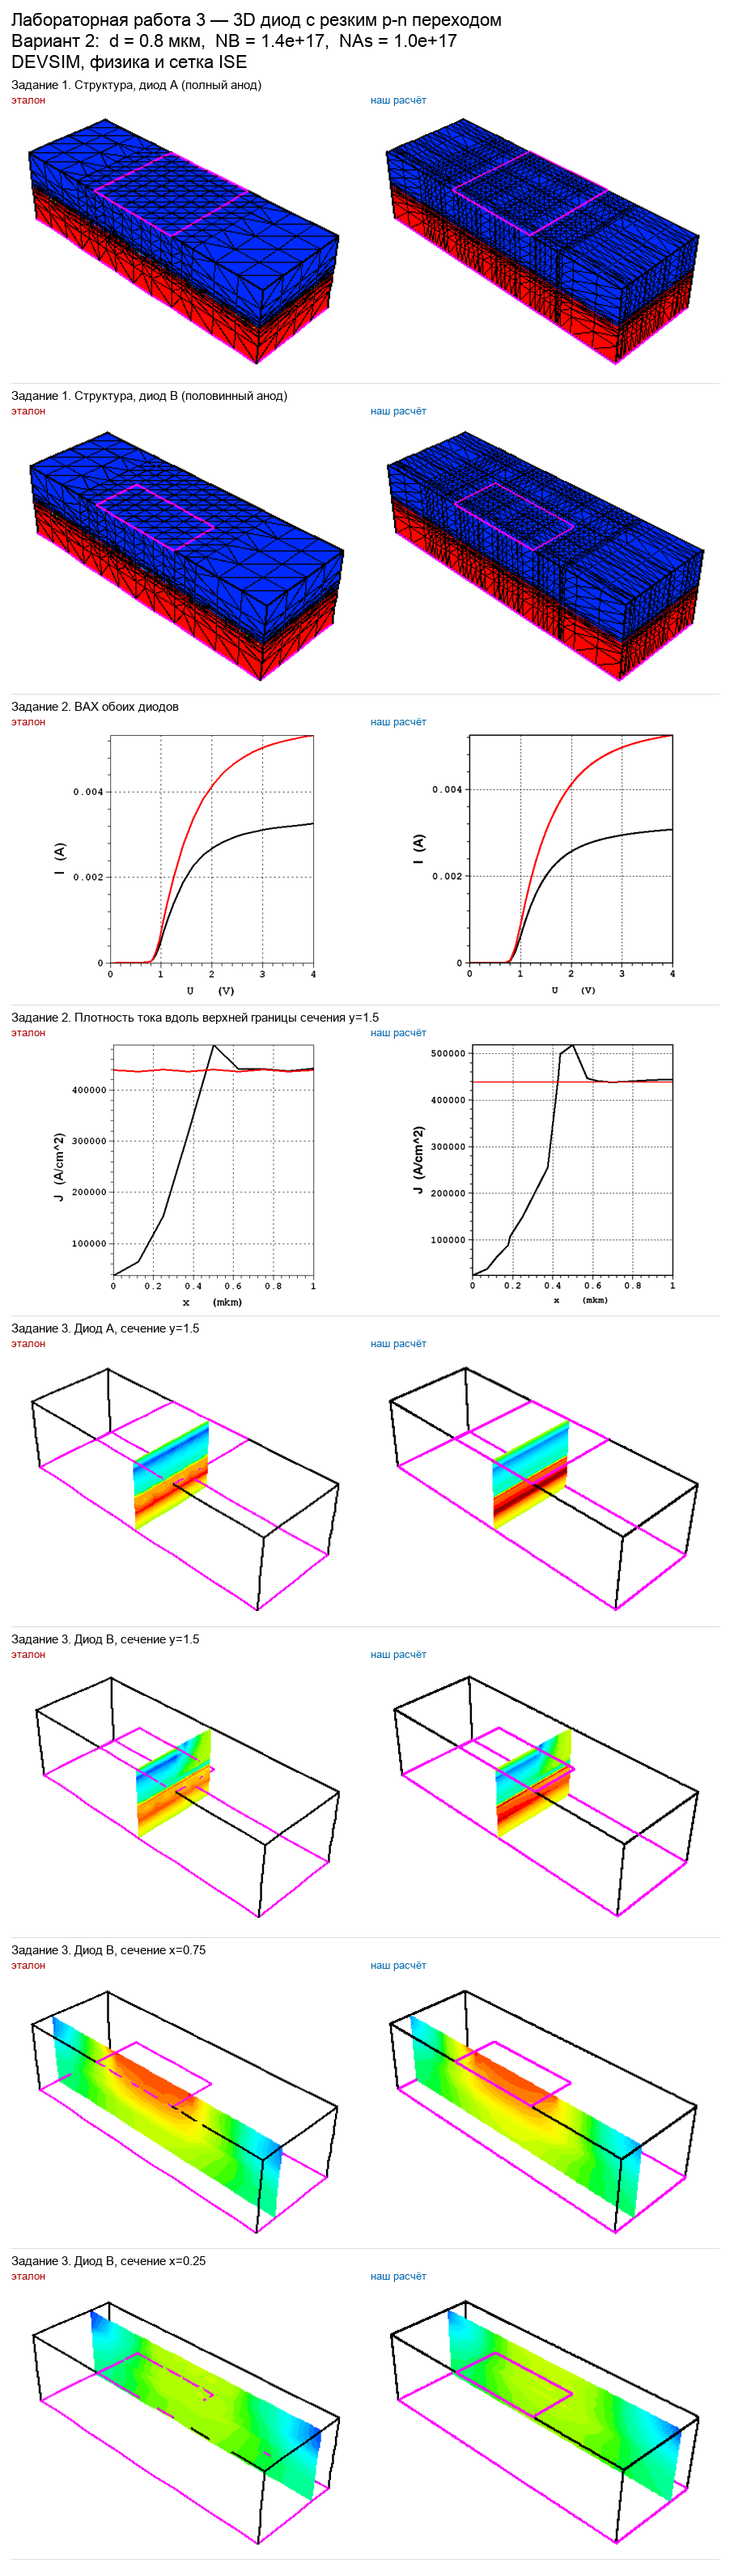

In [6]:
import make_figures as mf
if TENSOR == 1:
    mf.figures_devsim("devsim_ise", "field_ise_A_tensor1_clip.npz", "field_ise_B_tensor1_clip.npz",
                      "iv_ise_A_tensor1_clip.json", "iv_ise_B_tensor1_clip.json")
    mf.sheets()
display(Image(os.path.join(LAB, "results", "devsim_ise", "СВОДНЫЙ_ЛИСТ.png")))

### Вывод

_(совпадение с ISE на одной сетке, изменение токов при сгущении сетки)_